# Question 5: MNIST handwritten digit classification

In [38]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_openml
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.metrics import classification_report, accuracy_score, precision_recall_fscore_support

mnist = fetch_openml('mnist_784', version=1, as_frame=False)
mnist_df = pd.DataFrame(mnist.data, columns=mnist.feature_names)
mnist_df['target'] = mnist.target
mnist_df = mnist_df.sample(n=1000, random_state=42)

print(mnist_df.shape)
mnist_df.head()

(1000, 785)


,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,pixel10,...,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783,pixel784,target
46730,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,8
48393,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,4
41416,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,8
34506,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,7
43725,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,7


In [39]:
print(mnist_df['target'].value_counts().sort_index())

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

target
0     95
1    104
2     95
3    119
4     88
5     90
6     97
7    103
8    101
9    108
Name: count, dtype: int64


### Step 1 answer:

I chose k = 5 with stratified folds because with 1,000 images across 10 classes, each validation fold holds 200 images so that should be enough for a stable accuracy estimate. I use stratified folds because the sample is not exactly balanced and k = 10 would leave only about 10 images per digit per fold, making the estimate noisy.

## Step 2: Visualizations and analysis

X shape: (1000, 784)
pixel value range: 0.0 to 255.0


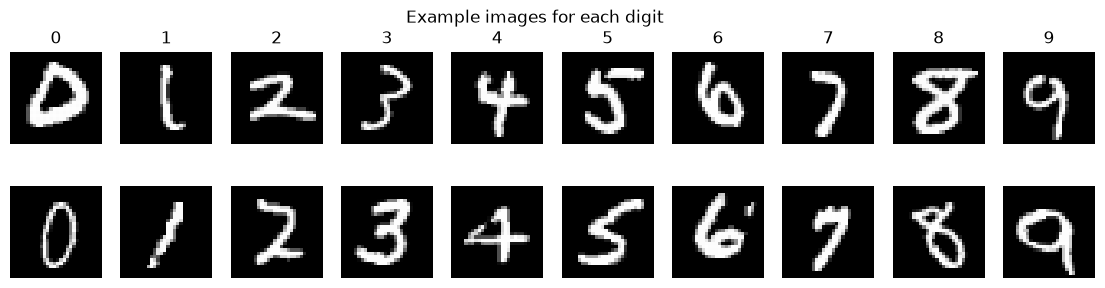

In [40]:
X = mnist_df.drop(columns='target').values.astype(float)
y = mnist_df['target'].to_numpy(dtype=str)  

print("X shape:", X.shape)
print("pixel value range:", X.min(), "to", X.max())

# Look at a few example images of each digit
fig, axes = plt.subplots(2, 10, figsize=(14, 3.2))
for d in range(10):
    idx = np.where(y == str(d))[0][:2]
    for r in range(2):
        axes[r, d].imshow(X[idx[r]].reshape(28, 28), cmap='gray')
        axes[r, d].axis('off')
        if r == 0:
            axes[r, d].set_title(str(d))
plt.suptitle("Example images for each digit")
plt.show()

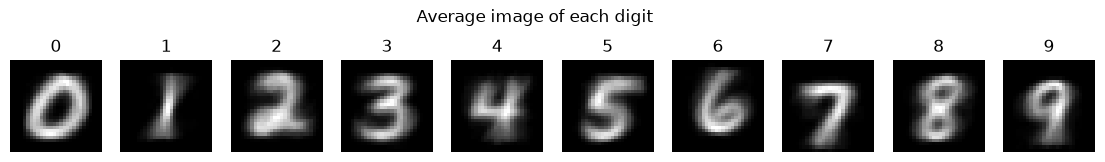

In [41]:
fig, axes = plt.subplots(1, 10, figsize=(14, 2))
for d in range(10):
    axes[d].imshow(X[y == str(d)].mean(axis=0).reshape(28, 28), cmap='gray')
    axes[d].set_title(str(d))
    axes[d].axis('off')
plt.suptitle("Average image of each digit")
plt.show()

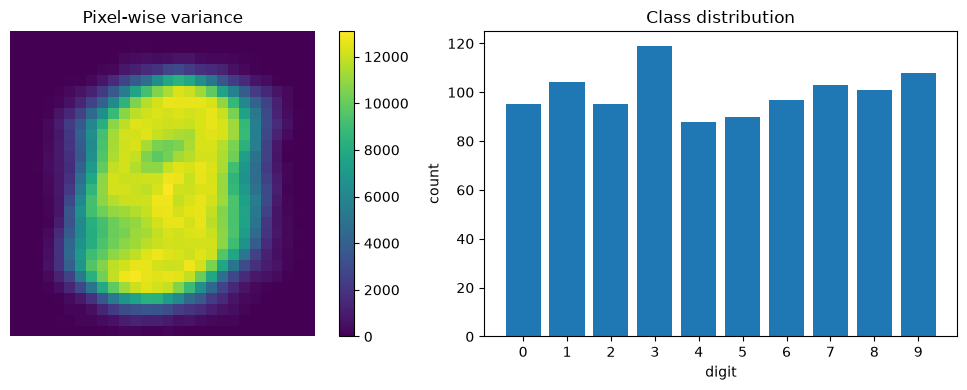

Pixels that are always 0: 183 out of 784


In [42]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))

im = ax[0].imshow(X.var(axis=0).reshape(28, 28), cmap='viridis')
ax[0].set_title("Pixel-wise variance")
ax[0].axis('off')
plt.colorbar(im, ax=ax[0], fraction=0.046)

counts = pd.Series(y).value_counts().sort_index()
ax[1].bar(counts.index, counts.values, color='tab:blue')
ax[1].set_title("Class distribution")
ax[1].set_xlabel("digit")
ax[1].set_ylabel("count")

plt.tight_layout()
plt.show()

print("Pixels that are always 0:", int((X.max(axis=0) == 0).sum()), "out of", X.shape[1])

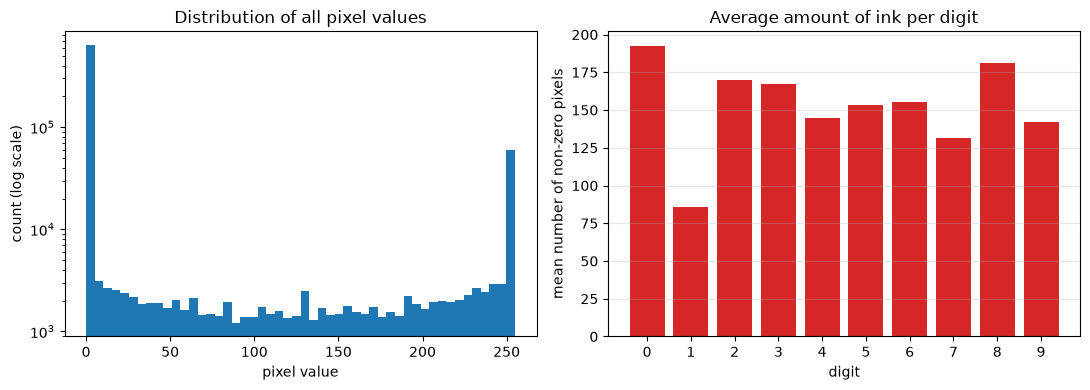

In [43]:
# Pixel value distribution, and how much "ink" each digit uses
fig, ax = plt.subplots(1, 2, figsize=(11, 4))

ax[0].hist(X.ravel(), bins=50, color='tab:blue')
ax[0].set_yscale('log')
ax[0].set_xlabel("pixel value")
ax[0].set_ylabel("count (log scale)")
ax[0].set_title("Distribution of all pixel values")

ink = [(X[y == str(d)] > 0).sum(axis=1).mean() for d in range(10)]
ax[1].bar(range(10), ink, color='tab:red')
ax[1].set_xlabel("digit")
ax[1].set_ylabel("mean number of non-zero pixels")
ax[1].set_title("Average amount of ink per digit")
ax[1].set_xticks(range(10))
ax[1].grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

### Step 2 analysis

The histogram shows that almost every pixel is either 0  or close to 255 , with very few values in between. 
We can also see 183 of the 784 pixels are 0 in every single image, and the variance map shows that all the useful variation sits in a blob in the middle of the frame. The border pixels are always black because the digits are centered which mean most pixels carry no information. Each class average is still a recognisable digit, which tells me the digits are centered and roughly the same size, so the same pixel tends to mean the same thing across images. SO The average images are clearly different from each other 

## Step 3: Assumptions from the visualization

Because every digit is centered and about the same size, a given pixel position means roughly the same thing in every image, so the raw pixel intensities can be used directly as features without any alignment step. The average images of the ten digits look clearly different from each other, so I assume the classes occupy different regions of the 784-dimensional pixel space and should be separable by both a distance-based model (k-NN) and a margin-based model (SVM). I also assume the boundaries are not perfectly linear, since the same digit can be written with shifted or thicker strokes.

## Step 4: Build the three models and evaluate them

In [44]:
X_scaled = X / 255.0

X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.3, random_state=42, stratify=y
)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)

results = []   
preds = {}     

def runner(model, name):
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    preds[name] = y_pred

    print(f"Classification Report for {name}:")
    print(classification_report(y_test, y_pred, digits=3))
    acc = accuracy_score(y_test, y_pred)
    cv_acc = cross_val_score(model, X_scaled, y, cv=cv).mean()
    print("Accuracy:", round(acc, 3))
    print("5-fold CV accuracy:", round(cv_acc, 3))

    if hasattr(model, "support_vectors_"):
        print("Support vectors per class:", model.n_support_)
        print("Total support vectors:", model.n_support_.sum(), "out of", len(X_train), "training images")

    p, r, f1, _ = precision_recall_fscore_support(y_test, y_pred, average='macro')
    results.append([name, p, r, f1, acc, cv_acc])
    return model

X_train shape: (700, 784)
X_test shape: (300, 784)


### (a) SVM with a linear kernel

In [45]:
svm_linear = runner(SVC(kernel="linear"), "SVM (linear kernel)")

Classification Report for SVM (linear kernel):
              precision    recall  f1-score   support

           0      0.933     0.966     0.949        29
           1      0.939     1.000     0.969        31
           2      0.862     0.862     0.862        29
           3      0.838     0.861     0.849        36
           4      0.926     0.962     0.943        26
           5      0.889     0.889     0.889        27
           6      0.903     0.966     0.933        29
           7      0.962     0.806     0.877        31
           8      0.958     0.767     0.852        30
           9      0.861     0.969     0.912        32

    accuracy                          0.903       300
   macro avg      0.907     0.905     0.904       300
weighted avg      0.906     0.903     0.902       300

Accuracy: 0.903
5-fold CV accuracy: 0.877
Support vectors per class: [34 38 50 42 47 54 47 41 59 56]
Total support vectors: 468 out of 700 training images


### (b) SVM with an RBF (Gaussian) kernel

In [46]:
svm_rbf = runner(SVC(kernel="rbf", gamma="scale"), "SVM (RBF kernel)")

Classification Report for SVM (RBF kernel):
              precision    recall  f1-score   support

           0      0.966     0.966     0.966        29
           1      0.886     1.000     0.939        31
           2      0.964     0.931     0.947        29
           3      0.969     0.861     0.912        36
           4      0.920     0.885     0.902        26
           5      1.000     0.963     0.981        27
           6      0.903     0.966     0.933        29
           7      0.893     0.806     0.847        31
           8      0.931     0.900     0.915        30
           9      0.811     0.938     0.870        32

    accuracy                          0.920       300
   macro avg      0.924     0.921     0.921       300
weighted avg      0.923     0.920     0.920       300

Accuracy: 0.92
5-fold CV accuracy: 0.898
Support vectors per class: [49 44 60 72 58 61 57 50 66 73]
Total support vectors: 590 out of 700 training images


### (c) k-NN model

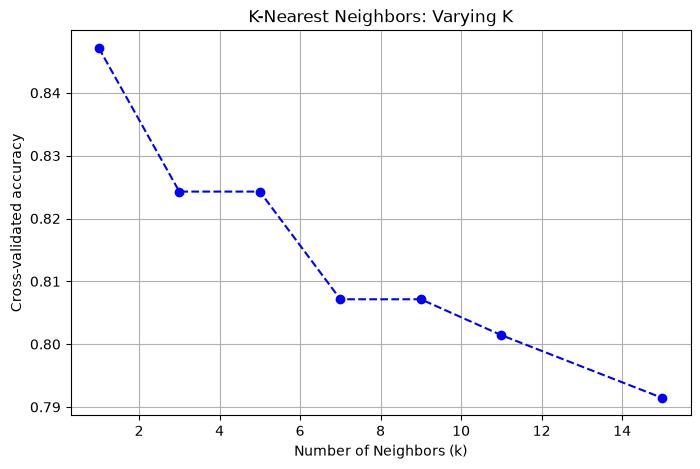

Accuracies for each k: {1: np.float64(0.847), 3: np.float64(0.824), 5: np.float64(0.824), 7: np.float64(0.807), 9: np.float64(0.807), 11: np.float64(0.801), 15: np.float64(0.791)}
Best k: 1


In [47]:
k_values = [1, 3, 5, 7, 9, 11, 15]
accuracies = []

for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)
    accuracies.append(cross_val_score(knn, X_train, y_train, cv=cv).mean())

plt.figure(figsize=(8, 5))
plt.plot(k_values, accuracies, marker='o', linestyle='--', color='b')
plt.title('K-Nearest Neighbors: Varying K')
plt.xlabel('Number of Neighbors (k)')
plt.ylabel('Cross-validated accuracy')
plt.grid(True)
plt.show()

best_k = k_values[int(np.argmax(accuracies))]
print("Accuracies for each k:", dict(zip(k_values, np.round(accuracies, 3))))
print("Best k:", best_k)

In [48]:
knn = runner(KNeighborsClassifier(n_neighbors=best_k), f"k-NN (k={best_k})")

Classification Report for k-NN (k=1):
              precision    recall  f1-score   support

           0      0.933     0.966     0.949        29
           1      0.795     1.000     0.886        31
           2      0.957     0.759     0.846        29
           3      0.917     0.917     0.917        36
           4      0.917     0.846     0.880        26
           5      1.000     0.852     0.920        27
           6      0.903     0.966     0.933        29
           7      0.812     0.839     0.825        31
           8      0.962     0.833     0.893        30
           9      0.833     0.938     0.882        32

    accuracy                          0.893       300
   macro avg      0.903     0.891     0.893       300
weighted avg      0.901     0.893     0.893       300

Accuracy: 0.893
5-fold CV accuracy: 0.864


In [49]:
summary = pd.DataFrame(results, columns=["Model", "Precision", "Recall",
                                         "F1-score", "Accuracy", "CV accuracy"])
summary.round(3)

,Model,Precision,Recall,F1-score,Accuracy,CV accuracy
0,SVM (linear kernel),0.907,0.905,0.904,0.903,0.877
1,SVM (RBF kernel),0.924,0.921,0.921,0.920,0.898
2,k-NN (k=1),0.903,0.891,0.893,0.893,0.864


## Step 5: Do the results support the assumptions?

Yes, the results match the assumptions in step 3. all three models reach about 0.89-0.92 accuracy with similar precision, recall, and F1, which confirms that raw centered pixels already separate the ten digits well. The RBF SVM is better than the linear SVM  and 1-NN. In summary, the SVMs keep only the hard boundary images as prototypes and are limited by needing a good kernel and C, while k-NN keeps all training images and is limited by the fact that plain pixel distance is easily thrown off by a small shift or stroke-thickness change.

## Step 6: What the metrics measure

Accuracy is the overall fraction of correctly labelled images 
Precision is how often a predicted digit is really that digit 
Recall is how many images of a true digit were actually found
F1 is the mean that balances the last two.
 For digit recognition the per-class precision and recall are the useful ones. The limitation is that a single number says nothing about *which* digits get confused with each other, so a confusion matrix is still needed, macro averaging treats every digit as equally important even though the sample is not perfectly balanced.